# 02 Statistical Reference Reproduction

**Scientific question.** What part of the published sparse benchmark can be reproduced?

**Learning objectives.** Derive lag designs, proxy innovations and distinct comparison conventions.

**Prerequisites.** Install the project requirements. Configure the data directory for raw-record checks. Portable evidence review also uses the existing run artifacts.

**Dataset and run.** Course gearbox at 3.2 kHz, the project’s designated training and held-out development records, and the explicit diagnostic or blind availability files where relevant.

**Execution.** This clean-kernel replay reads the evidence cited in each code cell. Use the explicit project pipeline for full fitting and the notebook build script for review replay. The companion guide contains notation, figures, and worked examples.

In [1]:
import hashlib
import json
import os
from pathlib import Path
import platform
import sys

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
get_ipython().run_line_magic("matplotlib", "inline")
from IPython.display import Image, display

hint = os.environ.get("SRC_PROJECT_DIR")
locations = [Path(hint).resolve()] if hint else [Path.cwd(), *Path.cwd().parents]
ROOT = next((p for p in locations if (p / "src" / "src_gearbox").is_dir()), None)
if ROOT is None:
    raise RuntimeError("Open within the project or set SRC_PROJECT_DIR.")
if str(ROOT / "src") not in sys.path:
    sys.path.insert(0, str(ROOT / "src"))
DATA = Path(os.environ.get("SRC_DATA_DIR", ROOT / "data" / "raw"))
RESULTS = ROOT / "results"
START = 1792
N = 24000
pd.options.display.max_colwidth = 120
pd.options.display.width = 115
plt.rcParams.update({"figure.dpi": 105, "axes.grid": True, "grid.alpha": .18})

def table(relative):
    file = ROOT / relative
    if not file.is_file():
        print(f"NOT AVAILABLE YET · {relative}")
        return None
    return pd.read_csv(file)

def evidence(relative):
    file = ROOT / relative
    if not file.is_file():
        print(f"NOT AVAILABLE YET · {relative}")
        return {}
    return json.loads(file.read_text(encoding="utf-8"))

def show_fig(relative, width=780):
    file = ROOT / relative
    if file.is_file():
        display(Image(filename=str(file), width=width))
    else:
        print(f"NOT AVAILABLE YET · {relative}")

def forecast(relative):
    file = ROOT / relative
    if not file.is_file():
        print(f"NOT AVAILABLE YET · {relative}")
        return {}
    with np.load(file, allow_pickle=False) as source:
        arrays = {key: source[key] for key in source.files}
    np.testing.assert_array_equal(arrays["target_indices"], np.arange(START, N))
    assert np.isfinite(arrays["actual"]).all()
    return arrays

def align_forecasts(reference, *others):
    for other in others:
        for key in ("target_indices", "actual", "rpm", "time_s"):
            np.testing.assert_array_equal(reference[key], other[key])

def draw_forecast(bundle, keys, view=slice(5000, 5200)):
    if not bundle:
        return
    y, t = bundle["actual"], bundle["time_s"]
    fig, ax = plt.subplots(2, 1, figsize=(9.0, 4.0), sharex=True, layout="constrained")
    ax[0].plot(t[view], y[view], color="#141a26", lw=1.2, label="Measured")
    for key, label in keys.items():
        if key in bundle:
            pred = bundle[key]
            ax[0].plot(t[view], pred[view], lw=0.9, label=label)
            ax[1].plot(t[view], (y-pred)[view], lw=0.9, label=label)
    ax[0].legend(ncol=3, fontsize=8)
    ax[0].set_ylabel("Std. vibration")
    ax[1].set(ylabel="Std. residual", xlabel="Acquisition time (s)")
    plt.show()

print("Read-only evidence replay.", f"Python {platform.python_version()}",
      f"NumPy {np.__version__}. One-step observed history through t−1.")

Read-only evidence replay. Python 3.12.14 NumPy 2.5.5. One-step observed history through t−1.


### From AR to sparse LPV-ARMA

With $\tilde e_j=x_j-\hat x^{(1)}_j$, the strict second stage uses
$\hat x_t=\sum_i a_i(s_{t-1})x_{t-i}+
\sum_j b_j(s_{t-1})\tilde e_{t-j}$.
A design column is a lag multiplied by a speed-basis value. Stage one
estimates proxy innovations, which must be available before each target.
ARIMA first predicts a differenced outcome and reconstructs the level
from earlier observed vibration. See Companion Chapters 4, 5 and 21.

AIC compares order candidates at the same target indices.
Sparse evidence requires the objective scale, solver criterion, and
estimation/selection policy. The local guarded support selection, QR
refit, archived coefficients, and authors' published Table 6 are
intentionally different evidence streams.

In [2]:
paper = table("results/metrics/published_paper_reference.csv")
local = table("results/metrics/local_statistical_reference.csv")
display(paper)
display(local)
if local is not None:
    k = local[(local.convention == "strict_development") & (local.model == "spa_lpv_arma")]
    if len(k):
        assert int(k.iloc[0].n) == 22208
sparse = evidence("results/metrics/strict_sparse_support_refit.json")
print("Support-reconciliation fields", list(sparse))

,model,train_mse,authors_test_segment_mse,authors_runs_p,doi,status
0,ari,0.4049,0.3658,0.0000,10.1016/j.ymssp.2024.112161,external_different_segment
1,arima,0.4034,0.3671,0.0000,10.1016/j.ymssp.2024.112161,external_different_segment
2,spa_lpv_ar,0.3001,0.2911,0.4356,10.1016/j.ymssp.2024.112161,external_different_segment
3,spa_lpv_arma,0.3099,0.2893,0.6233,10.1016/j.ymssp.2024.112161,external_different_segment


,model,convention,scheduling,start,n,train_mse,development_mse,common_mask_mse,runs_p
0,ari,strict_development,previous,1792,22208,0.415067,0.425069,0.425069,0.626234
1,arima,strict_development,previous,1792,22208,0.414353,0.425223,0.425223,0.483642
2,spa_lpv_ar,strict_development,previous,1792,22208,0.348991,0.381496,0.381496,0.466772
3,spa_lpv_arma,strict_development,previous,1792,22208,0.347764,0.371406,0.371406,0.248863
4,lpv_ar_dense,strict_development,previous,1792,22208,0.290950,0.344585,0.344585,0.686573
5,lpv_arma_dense,strict_development,previous,1792,22208,0.292922,0.330781,0.330781,0.050963
6,ari,preserved_archive_current_rpm,current,316,23684,0.405993,0.415816,0.425669,0.546688
7,arima,preserved_archive_current_rpm,current,316,23684,0.405762,0.415719,0.425436,0.599757
8,spa_lpv_ar,preserved_archive_current_rpm,current,316,23684,0.301960,0.340886,0.349844,0.725853
9,spa_lpv_arma,preserved_archive_current_rpm,current,316,23684,0.310976,0.336901,0.345151,0.054596


Support-reconciliation fields ['source_checkpoint_sha256', 'coefficient_max_abs_delta', 'stage1_fit_s', 'two_stage_fit_s', 'status', 'note']


In [3]:
from numpy.polynomial.legendre import legvander

x = np.array([1., 3., 2., 5., 8.])
report_idx = np.array([2, 3, 4])
lag_count = np.array([1, 2])
lags = x[report_idx[:, None] - lag_count]
operating_state = np.array([-.8, -.2, .5, .8, 1.])
sched = legvander(operating_state[report_idx-1], 2)
design = (lags[:,:,None]*sched[:,None,:]).reshape(3, 6)
np.testing.assert_array_equal(design[:, ::3], lags)
display(pd.DataFrame(design).round(3))

,0,1,2,3,4,5
0,3.0,-0.6,-1.32,1.0,-0.2,-0.440
1,2.0,1.0,-0.25,3.0,1.5,-0.375
2,5.0,4.0,2.30,2.0,1.6,0.920


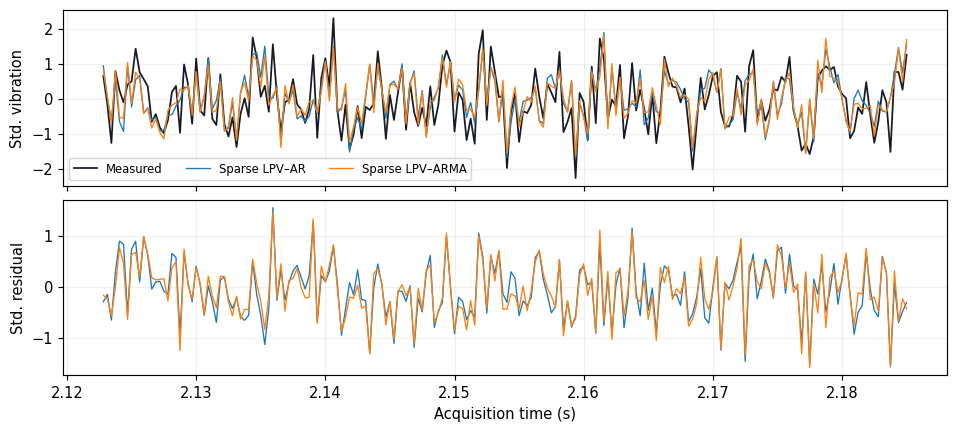

In [4]:
paired = forecast("results/predictions/baselines_sigvalid.npz")
draw_forecast(paired, {"sparse_lpv_ar":"Sparse LPV–AR",
                       "sparse_lpv_arma":"Sparse LPV–ARMA"})

### Interpretation and limits

Current-speed retrospective and random-row historical conventions describe the
source reconstruction. They do not enter the strict ranking without the matching
history and mask. The published test segment has a different provenance. A lower
value on that segment does not imply direct paired superiority.

Read the [Companion Guide](../docs/companion_guide.md) and the [Project README](../README.md).